# 05 — Volatility Engine

ATR, realized volatility, EWMA volatility and volatility percentile.


In [1]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path


def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")


project_root = find_project_root()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)


Project root: /Users/jamesb/Desktop/vietnam-quant-research


In [2]:
# Cell: Import Volatility Modules
from src.data.loaders import read_parquet, save_parquet
from src.features.returns import add_returns
from src.features.volatility import (
    add_atr,
    add_realized_volatility,
    add_ewma_volatility,
    add_volatility_percentile,
    classify_volatility_regime,
)
from src.features.trend import add_moving_averages
from src.features.distribution import add_rolling_distribution_stats
from src.features.liquidity import add_liquidity_features


In [3]:
# Cell: Build Volatility Features
clean = read_parquet("data/processed/clean_daily_ohlcv.parquet")
features = add_returns(clean)
features = add_atr(features, window=14)
features = add_realized_volatility(features, window=20)
features = add_ewma_volatility(features, span=20)
features = add_volatility_percentile(features, vol_col="realized_vol_20d", window=252)
features = classify_volatility_regime(features)
features.shape


(718709, 25)

In [4]:
# Cell: Inspect Volatility Outputs
features[["symbol", "date", "close", "atr_pct_14", "realized_vol_20d", "volatility_percentile", "volatility_regime"]].sort_values(["symbol", "date"]).groupby("symbol").tail(3)


,symbol,date,close,atr_pct_14,realized_vol_20d,volatility_percentile,volatility_regime
648,A32,2026-07-15,29605,0.047622,0.834105,0.468254,Normal Vol
649,A32,2026-07-20,31000,0.041551,0.852176,0.484127,Normal Vol
650,A32,2026-07-22,31000,0.033486,0.833654,0.468254,Normal Vol
2282,AAA,2026-07-20,6870,0.025920,0.236466,0.392857,Normal Vol
2283,AAA,2026-07-21,6870,0.027376,0.236466,0.390873,Normal Vol
...,...,...,...,...,...,...,...
717075,YBM,2026-07-20,9660,0.020482,0.265111,0.297619,Normal Vol
717076,YBM,2026-07-21,9660,0.019151,0.265111,0.299603,Normal Vol
718706,YEG,2026-07-20,7660,0.037952,0.440456,0.797619,Stress Vol
718707,YEG,2026-07-21,7710,0.037058,0.407643,0.702381,High Vol


In [5]:
# Cell: Save Volatility Features & Full Stock Features
# GUARDED WRITE (docs/reports/codebase_audit/MARKET_REGIME_AUDIT.md NV1): this
# path is the shared production stock_features.parquet, canonically produced
# by `python scripts/generate_features.py` from full_history_v2 with the full
# feature set (49 cols). This notebook only builds a subset of those columns
# -- running it by hand used to silently overwrite the production file with
# an incomplete version. Default: skip the write, just show the regime
# breakdown. Set ALLOW_PRODUCTION_WRITE=1 before starting the kernel if you
# really mean to overwrite it by hand.
from src.data.production_guard import guard_production_write, ProductionWriteBlocked

features = add_moving_averages(features, windows=[20, 50, 200])
features = add_rolling_distribution_stats(features, window=60)
features = add_liquidity_features(features)

output_path = "data/processed/stock_features.parquet"
try:
    guard_production_write(output_path)
    save_parquet(features, output_path)
    print(f"Da ghi {output_path} (ALLOW_PRODUCTION_WRITE=1).")
except ProductionWriteBlocked as e:
    print(f"KHONG ghi {output_path} -- {e}")

features["volatility_regime"].value_counts(dropna=False)


KHONG ghi data/processed/stock_features.parquet -- Refusing to write data/processed/stock_features.parquet -- this is a shared production file read by ~20 other scripts/modules (build_portfolio_stack.py, run_alpha_scoring.py, final_watchlist.py, ...). The canonical way to regenerate it is `python scripts/generate_features.py`, not this notebook. If you really mean to overwrite it by hand (e.g. debugging), set ALLOW_PRODUCTION_WRITE=1 before starting the kernel, or pass allow=True to guard_production_write(). See docs/reports/codebase_audit/MARKET_REGIME_AUDIT.md for the incident this guards against.


volatility_regime
Normal Vol    163694
Low Vol       139204
Unknown       137654
High Vol      132942
Stress Vol     79929
Panic Vol      65286
Name: count, dtype: int64

## Volatility Regime Visualizations

The following sections plot the volatility estimators, market-wide regime distributions, macro volatility regimes over time, and cross-sectional volatility dispersion.

In [6]:
# Cell: Setup Visualizations and Styles
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Set styling using custom rcParams
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 150,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": ":"
})


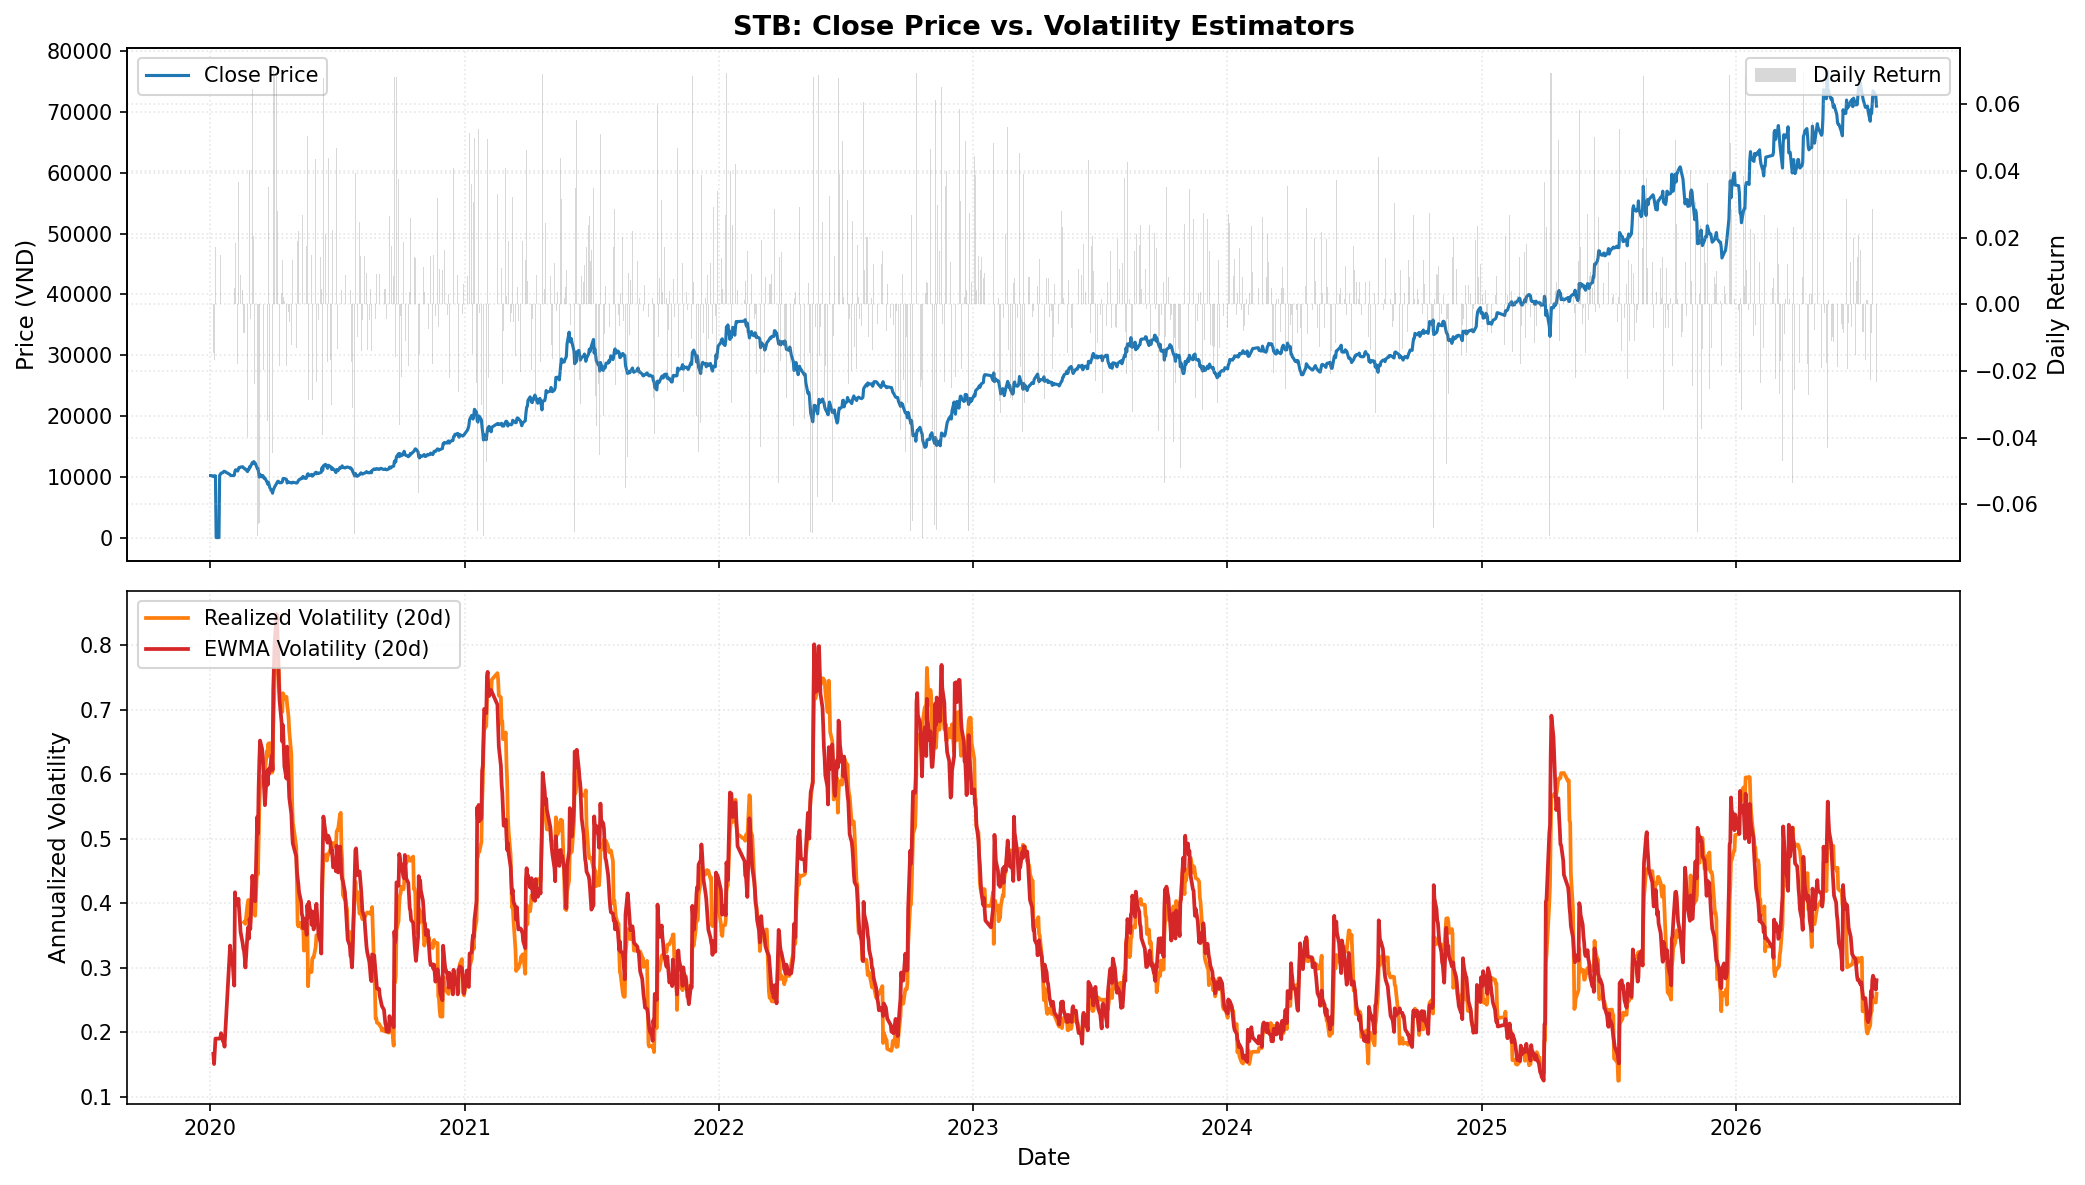

In [7]:
# Cell: Plot 1 - Comparison of Volatility Estimators (Selected Ticker)
# Choose a representative liquid stock (e.g. STB or first available)
sample_symbol = "STB" if "STB" in features["symbol"].values else features["symbol"].iloc[0]
stock_df = features[features["symbol"] == sample_symbol].sort_values("date").copy()

# Convert date to datetime
stock_df["date"] = pd.to_datetime(stock_df["date"])

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Subplot 1: Price and Returns
axes[0].plot(stock_df["date"], stock_df["close"], color="#1f77b4", linewidth=1.5, label="Close Price")
axes[0].set_ylabel("Price (VND)", fontsize=11)
axes[0].set_title(f"{sample_symbol}: Close Price vs. Volatility Estimators", fontsize=13, fontweight="bold")
axes[0].legend(loc="upper left")

# Secondary y-axis for daily returns
ax_ret = axes[0].twinx()
ax_ret.bar(stock_df["date"], stock_df["return_1d"], color="gray", alpha=0.3, label="Daily Return")
ax_ret.set_ylabel("Daily Return", fontsize=11)
ax_ret.legend(loc="upper right")

# Subplot 2: Realized vs. EWMA Volatility (Annualized)
axes[1].plot(stock_df["date"], stock_df["realized_vol_20d"], color="#ff7f0e", linewidth=1.8, label="Realized Volatility (20d)")
if "ewma_vol_20d" in stock_df.columns:
    axes[1].plot(stock_df["date"], stock_df["ewma_vol_20d"], color="#d62728", linewidth=1.8, label="EWMA Volatility (20d)")
axes[1].set_ylabel("Annualized Volatility", fontsize=11)
axes[1].set_xlabel("Date", fontsize=11)
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()


/var/folders/qv/3db8g9b965s_3_m93smxd__40000gn/T/ipykernel_75214/1019347771.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(regime_counts.index, rotation=30)


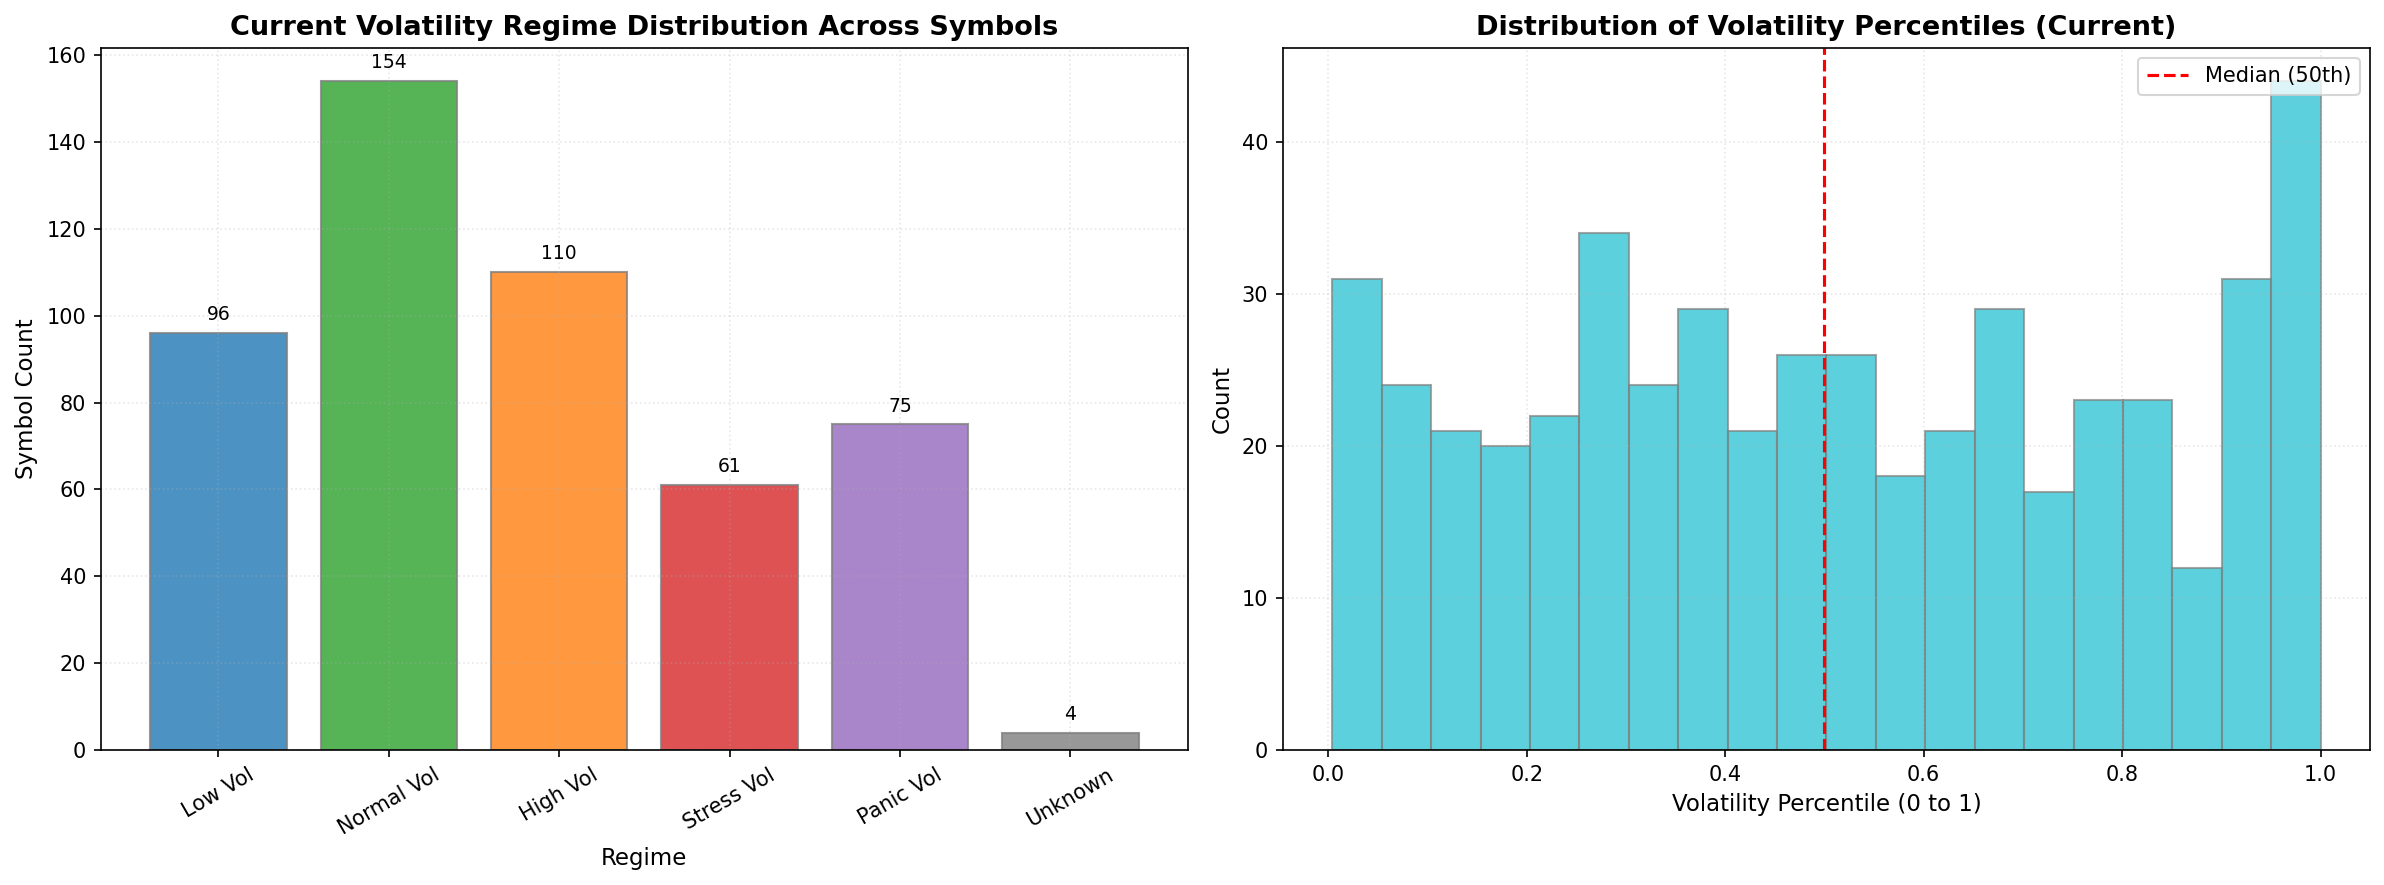

In [8]:
# Cell: Plot 2 - Market-wide Volatility Regime Distribution
latest_stats = features.sort_values("date").groupby("symbol").last().reset_index()

# Filter out symbols without valid regimes
latest_stats = latest_stats.dropna(subset=["volatility_regime"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot A: Volatility Regime Bar Chart
regime_order = ["Low Vol", "Normal Vol", "High Vol", "Stress Vol", "Panic Vol", "Unknown"]
regime_counts = latest_stats["volatility_regime"].value_counts().reindex(regime_order).fillna(0)
colors = ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728", "#9467bd", "#7f7f7f"]

axes[0].bar(regime_counts.index, regime_counts.values, color=colors, alpha=0.8, edgecolor="gray")
axes[0].set_title("Current Volatility Regime Distribution Across Symbols", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Regime", fontsize=11)
axes[0].set_ylabel("Symbol Count", fontsize=11)
axes[0].set_xticklabels(regime_counts.index, rotation=30)
for i, v in enumerate(regime_counts.values):
    axes[0].text(i, v + 2, str(int(v)), ha="center", va="bottom", fontsize=9)

# Subplot B: Volatility Percentile Histogram
axes[1].hist(latest_stats["volatility_percentile"].dropna(), bins=20, color="#17becf", alpha=0.7, edgecolor="gray")
axes[1].set_title("Distribution of Volatility Percentiles (Current)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Volatility Percentile (0 to 1)", fontsize=11)
axes[1].set_ylabel("Count", fontsize=11)
axes[1].axvline(0.5, color="red", linestyle="--", linewidth=1.5, label="Median (50th)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


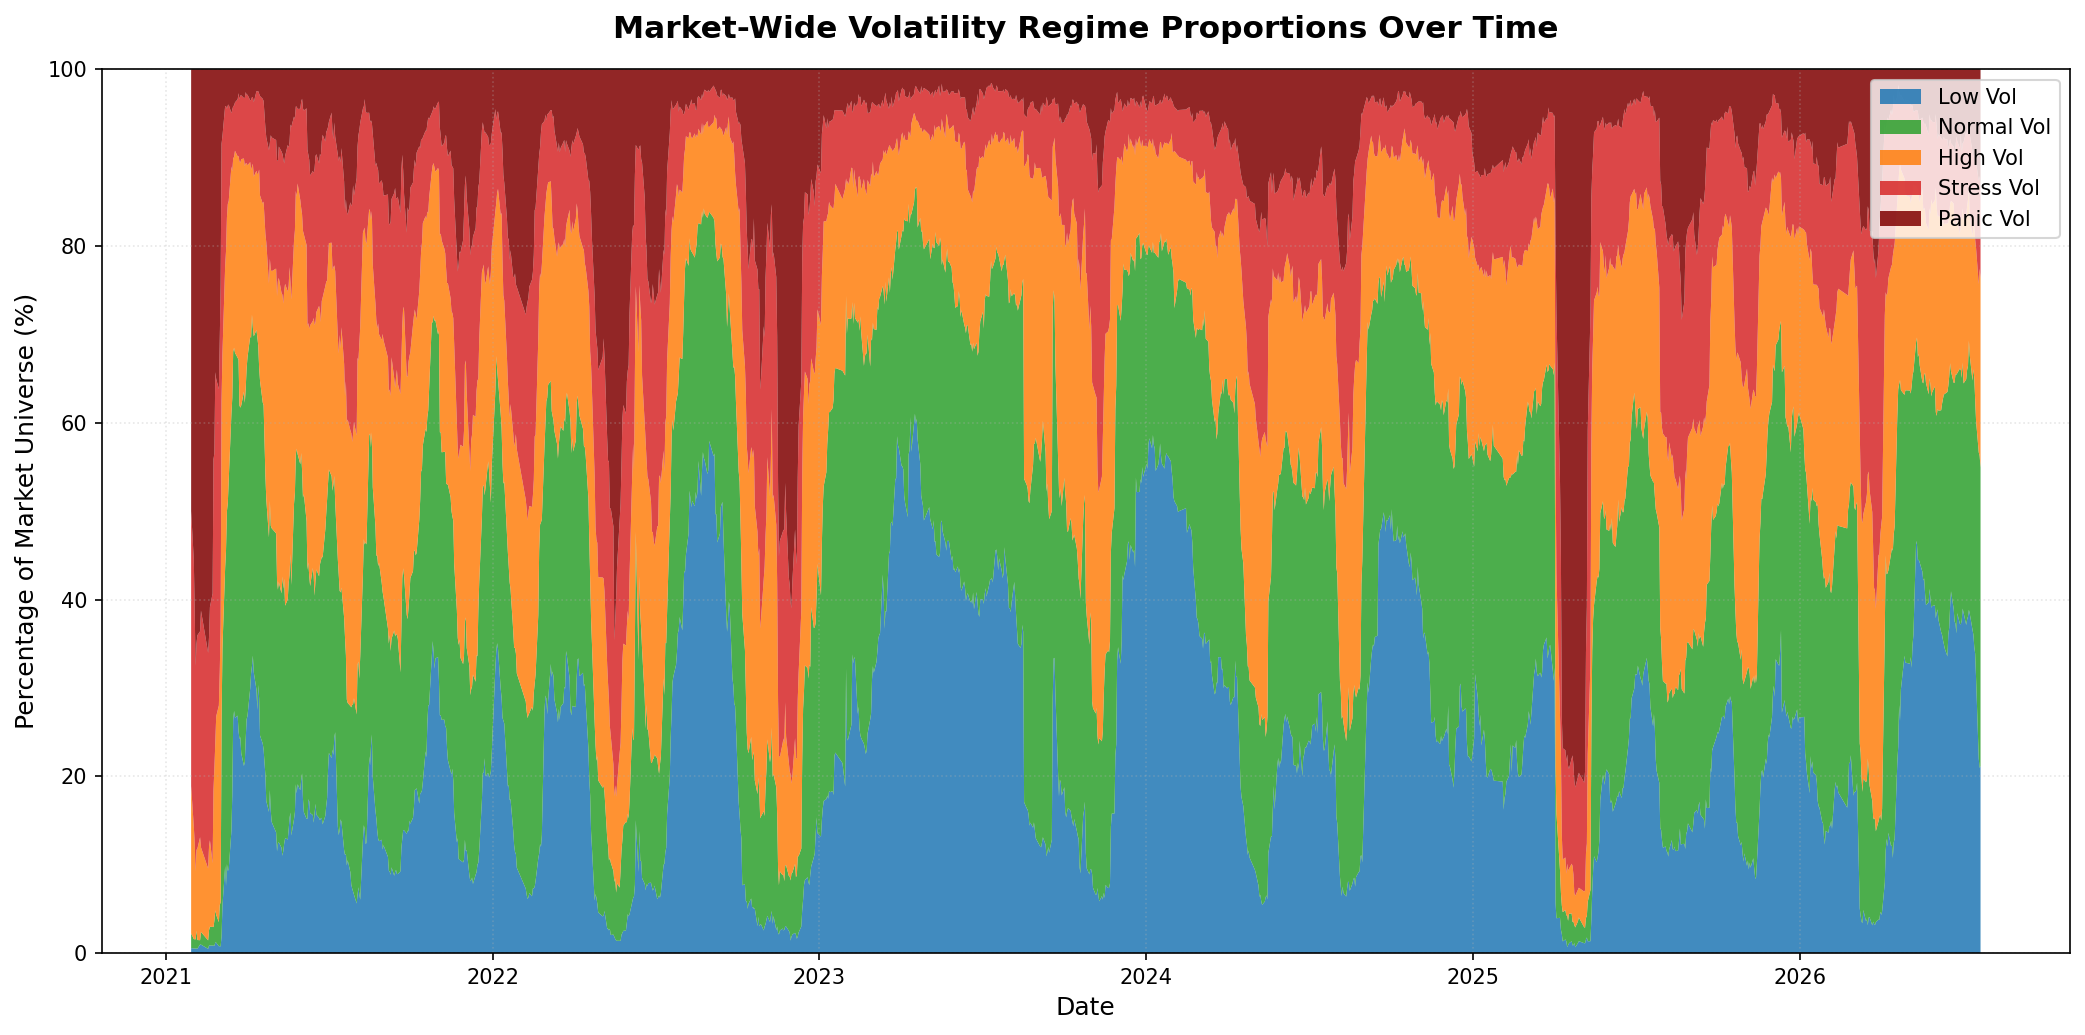

In [9]:
# Cell: Plot 3 - Time Series of Market-Wide Volatility Regimes (Stacked Area Chart)
# Group by date and count the percentage of stocks in each volatility regime
regime_ts = features.groupby(["date", "volatility_regime"]).size().unstack(fill_value=0)

# Sort regimes in logical volatility order
regime_cols = [c for c in ["Low Vol", "Normal Vol", "High Vol", "Stress Vol", "Panic Vol"] if c in regime_ts.columns]
regime_ts = regime_ts[regime_cols]

# Calculate percentage of total stocks per date
regime_pct = regime_ts.div(regime_ts.sum(axis=1), axis=0) * 100.0
regime_pct.index = pd.to_datetime(regime_pct.index)

fig, ax = plt.subplots(figsize=(14, 7))

# Area plot colors corresponding to volatility levels (Low to high)
colors_stack = ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728", "#7f0000"]

ax.stackplot(
    regime_pct.index, 
    [regime_pct[col] for col in regime_cols],
    labels=regime_cols, 
    colors=colors_stack[:len(regime_cols)], 
    alpha=0.85
)

ax.set_title("Market-Wide Volatility Regime Proportions Over Time", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Percentage of Market Universe (%)", fontsize=12)
ax.set_ylim(0, 100)
ax.legend(loc="upper right", frameon=True, facecolor="white")
ax.grid(True, linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()


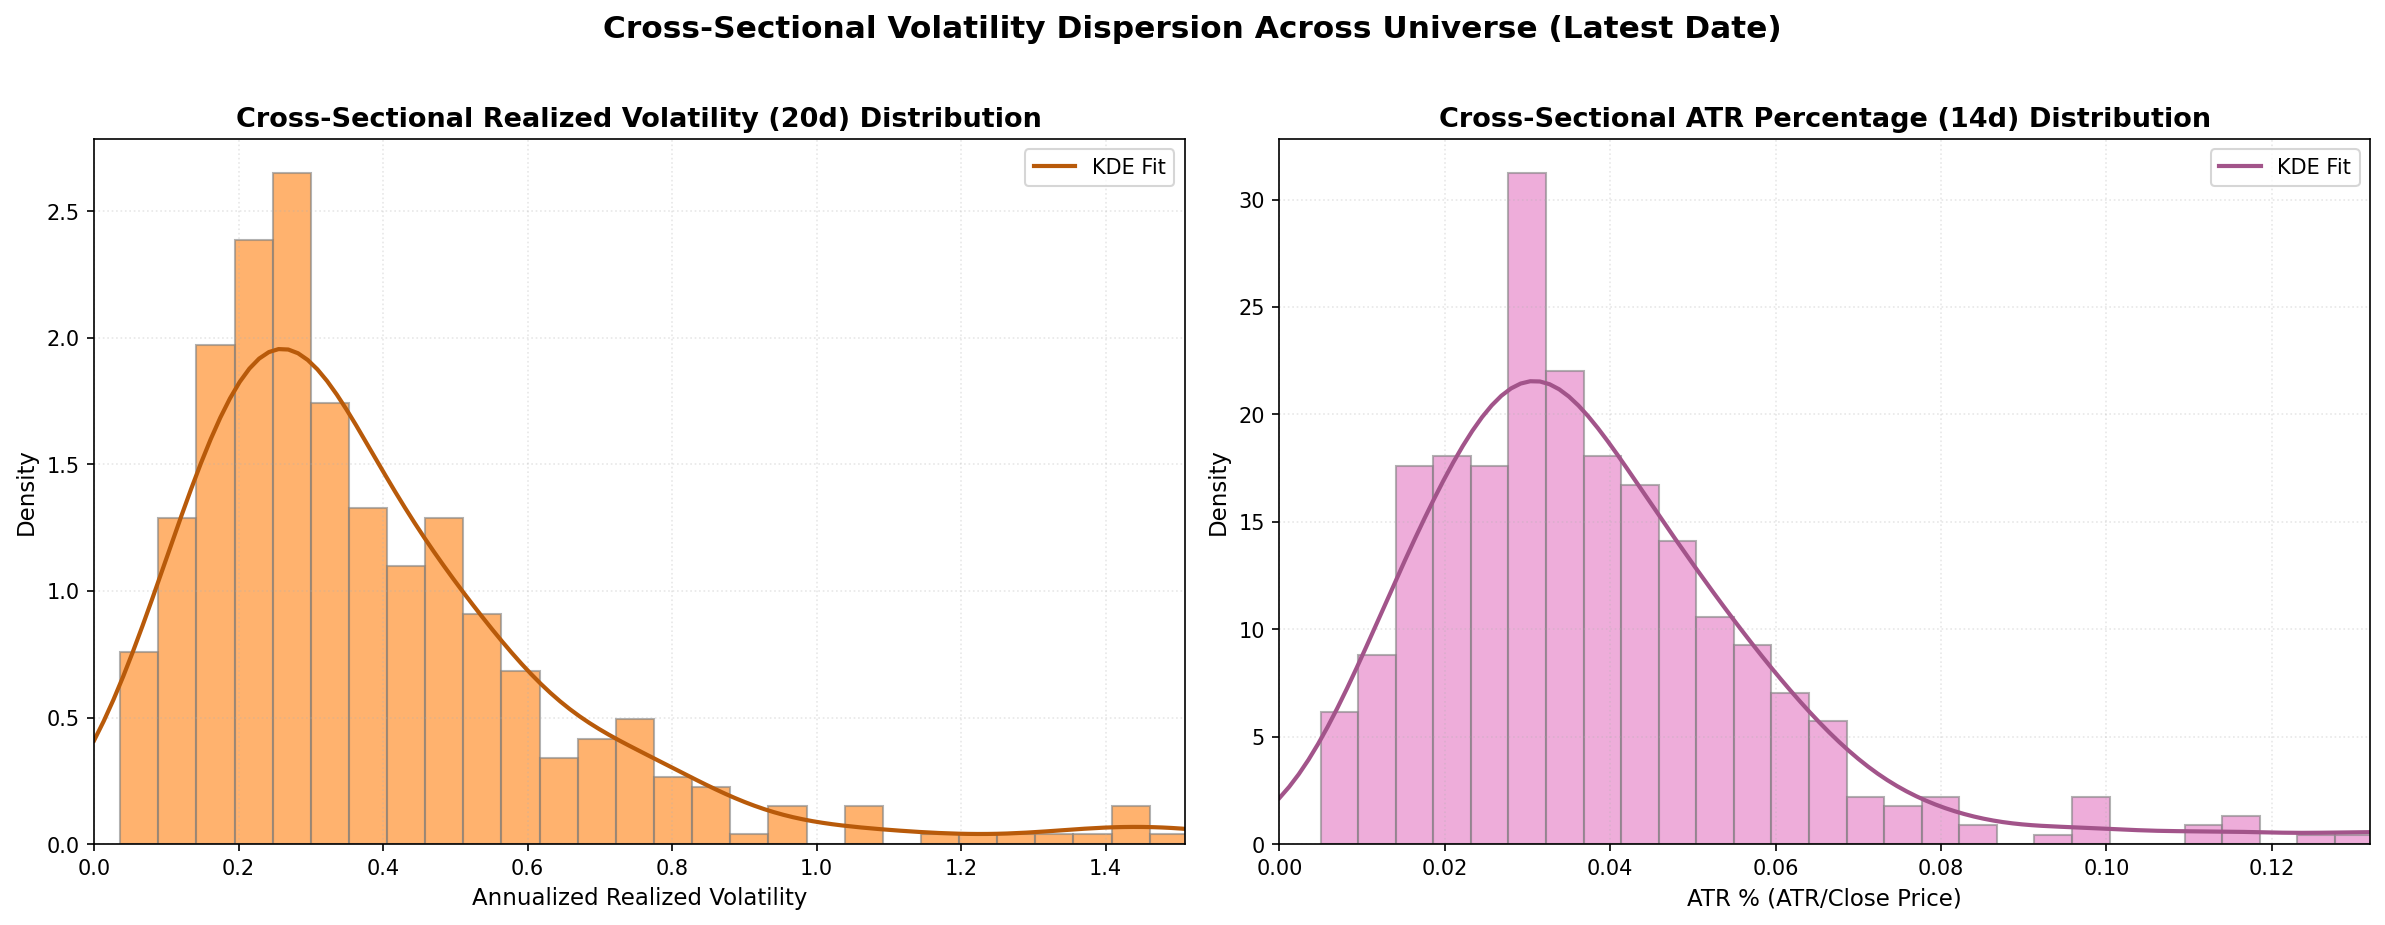

In [10]:
# Cell: Plot 4 - Cross-Sectional Volatility Distribution (Latest Date)
# Analyze current volatility dispersion across all symbols
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

latest_stats = latest_stats.dropna(subset=["realized_vol_20d", "atr_pct_14"])

# Subplot 1: Realized Volatility distribution
axes[0].hist(latest_stats["realized_vol_20d"], bins=50, density=True, color="#ff7f0e", alpha=0.6, edgecolor="gray")
try:
    kde_vol = stats.gaussian_kde(latest_stats["realized_vol_20d"])
    x_vol = np.linspace(0, latest_stats["realized_vol_20d"].max(), 200)
    axes[0].plot(x_vol, kde_vol(x_vol), color="#b85a0a", linewidth=2, label="KDE Fit")
except:
    pass
# Cap x range for visualization if there are massive outlier values
axes[0].set_xlim(0, min(latest_stats["realized_vol_20d"].quantile(0.98), 2.0))
axes[0].set_title("Cross-Sectional Realized Volatility (20d) Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Annualized Realized Volatility", fontsize=11)
axes[0].set_ylabel("Density", fontsize=11)
axes[0].legend(loc="upper right")

# Subplot 2: ATR Percent distribution
axes[1].hist(latest_stats["atr_pct_14"], bins=50, density=True, color="#e377c2", alpha=0.6, edgecolor="gray")
try:
    kde_atr = stats.gaussian_kde(latest_stats["atr_pct_14"])
    x_atr = np.linspace(0, latest_stats["atr_pct_14"].max(), 200)
    axes[1].plot(x_atr, kde_atr(x_atr), color="#a2548a", linewidth=2, label="KDE Fit")
except:
    pass
# Cap x range for visualization
axes[1].set_xlim(0, min(latest_stats["atr_pct_14"].quantile(0.98), 0.15))
axes[1].set_title("Cross-Sectional ATR Percentage (14d) Distribution", fontsize=13, fontweight="bold")
axes[1].set_xlabel("ATR % (ATR/Close Price)", fontsize=11)
axes[1].set_ylabel("Density", fontsize=11)
axes[1].legend(loc="upper right")

plt.suptitle("Cross-Sectional Volatility Dispersion Across Universe (Latest Date)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()
